In [1]:
library(dplyr)
library(Seurat)
library(patchwork)
library(ggplot2)
library(sctransform)
# library(glmGamPoi)
# library(cluster)
# library(Matrix)
# library(fitdistrplus)
# library(stats)
# library(cgwtools)
# library(stringr)
# library(SeuratDisk)
# library(limma)
# library(RColorBrewer)
# library(DESeq2)
# library(MAST)
# library(rlist)
# library(EnhancedVolcano)

#use .udunits-2.2.28


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


The legacy packages maptools, rgdal, and rgeos, underpinning the sp package,
which was just loaded, will retire in October 2023.
Please refer to R-spatial evolution reports for details, especially
https://r-spatial.org/r/2023/05/15/evolution4.html.
It may be desirable to make the sf package available;
package maintainers should consider adding sf to Suggests:.
The sp package is now running under evolution status 2
     (status 2 uses the sf package in place of rgdal)

Attaching SeuratObject

Warning message:
“package ‘patchwork’ was built under R version 4.2.1”
Warning message:
“package ‘sctransform’ was built under R version 4.2.1”


# New Script

In [78]:
library(Seurat)

process_lane <- function(lane_number) {
  # Construct the file path based on the lane number
  file_path <- paste0("/Genomics/pritykinlab/share/perturbseq/fromMarc/new_data/trim28_setdb1_data/analysis/Lane", lane_number, "/filtered_feature_bc_matrix.h5")
  
  # Load Lane data
  lane_data <- Read10X_h5(file_path)
  
  # Create Seurat object for the lane
  lane <- CreateSeuratObject(counts = lane_data[["Gene Expression"]], min.cells = 10, min.features = 400, project = paste0("lane", lane_number))
  lane[["gRNA"]] <- CreateAssayObject(lane_data[["CRISPR Guide Capture"]][, colnames(x = lane)], min.cells = 5)
  lane.hto <- lane_data[["Antibody Capture"]]
  
  if (lane_number <= 8) {
    hashtags_to_keep <- c("Hashtag1", "Hashtag2", "Hashtag3", "Hashtag4", "Hashtag5", "Hashtag6", "Hashtag7", "Hashtag8", "Hashtag9", "Hashtag10", "Hashtag11", "Hashtag12")
  } else {
    hashtags_to_keep <- c("Hashtag13", "Hashtag14", "Hashtag15", "Hashtag16", "Hashtag17", "Hashtag18", "Hashtag19", "Hashtag20", "Hashtag21", "Hashtag22", "Hashtag23", "Hashtag24")
  }
  lane.hto <- lane.hto[which(rownames(lane.hto) %in% hashtags_to_keep),]
  
  # Add the filtered HTO data to the Seurat object
  lane[["HTO"]] <- CreateAssayObject(lane.hto[, colnames(x = lane)], min.cells = 5)
  
  # Extract the "Antibody Capture" assay data
  hto_matrix <- GetAssayData(lane, assay = "HTO", slot = "counts")
  
  # Calculate the total count of each hashtag across cells
  total_counts_per_hashtag <- rowSums(hto_matrix)
  
  # Normalize HTO data
  lane <- NormalizeData(lane, assay = "HTO", normalization.method = "CLR", margin = 2, verbose = FALSE)
  
  # Run HTODemux
  lane <- HTODemux(lane, assay = "HTO", positive.quantile = 0.99)
  
  # Return the total counts and the processed Seurat object
  list(total_counts_per_hashtag = total_counts_per_hashtag, lane = lane)
}

# Process all lanes from 1 to 16
results <- lapply(1:16, process_lane)

Genome matrix has multiple modalities, returning a list of matrices for this genome

Cutoff for Hashtag1 : 6 reads

Cutoff for Hashtag2 : 9 reads

Cutoff for Hashtag3 : 6 reads

Cutoff for Hashtag4 : 6 reads

Cutoff for Hashtag5 : 6 reads

Cutoff for Hashtag6 : 11 reads

Cutoff for Hashtag7 : 14 reads

Cutoff for Hashtag8 : 3 reads

Cutoff for Hashtag9 : 5 reads

Cutoff for Hashtag10 : 3 reads

Cutoff for Hashtag11 : 8 reads

Cutoff for Hashtag12 : 32 reads

Genome matrix has multiple modalities, returning a list of matrices for this genome

Cutoff for Hashtag1 : 249 reads

Cutoff for Hashtag2 : 214 reads

Cutoff for Hashtag3 : 77 reads

Cutoff for Hashtag4 : 300 reads

Cutoff for Hashtag5 : 440 reads

Cutoff for Hashtag6 : 649 reads

Cutoff for Hashtag7 : 151 reads

Cutoff for Hashtag8 : 20 reads

Cutoff for Hashtag9 : 580 reads

Cutoff for Hashtag10 : 164 reads

Cutoff for Hashtag11 : 803 reads

Cutoff for Hashtag12 : 1388 reads

Genome matrix has multiple modalities, returning a lis

 Hashtag1  Hashtag2  Hashtag3  Hashtag4  Hashtag5  Hashtag6  Hashtag7  Hashtag8 
   125538    311212     94200     58626     63892    211765    395913     49215 
 Hashtag9 Hashtag10 Hashtag11 Hashtag12 
    66855    103324    106602   1074233 


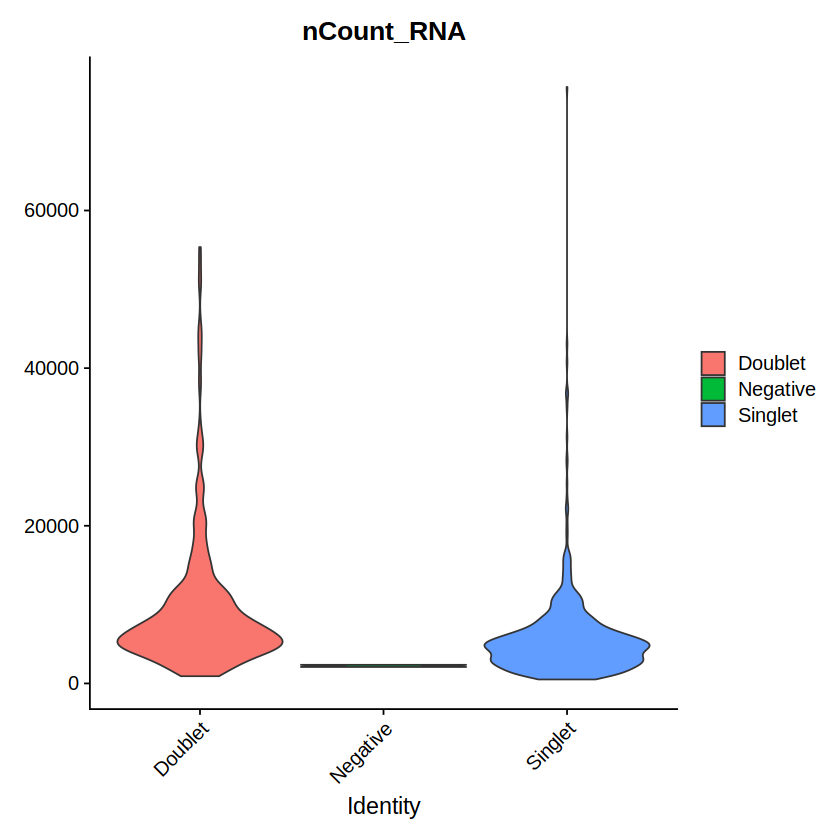

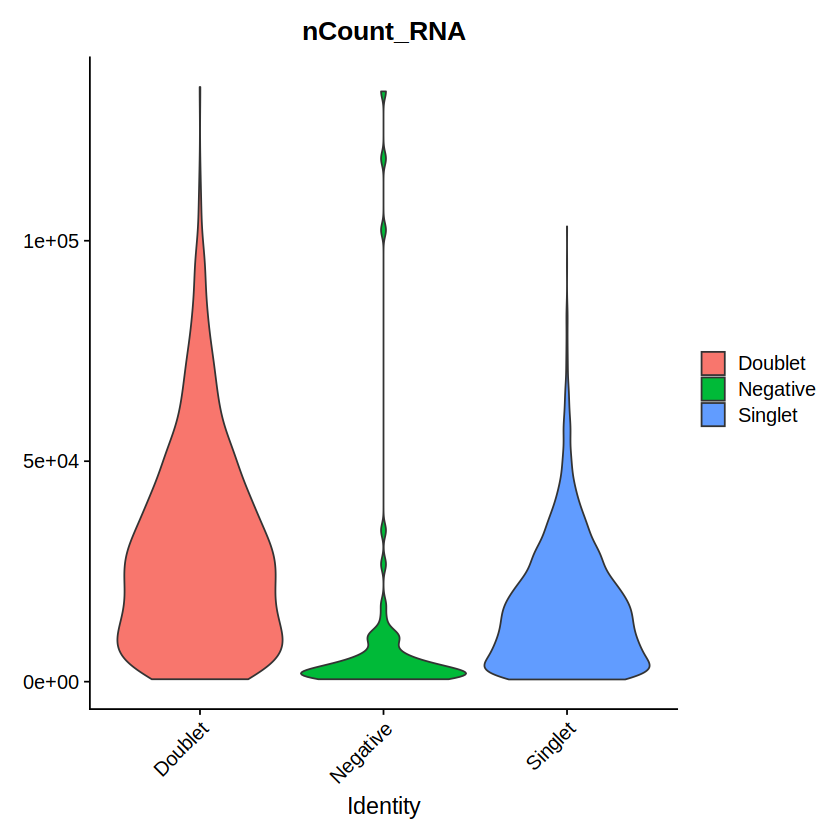

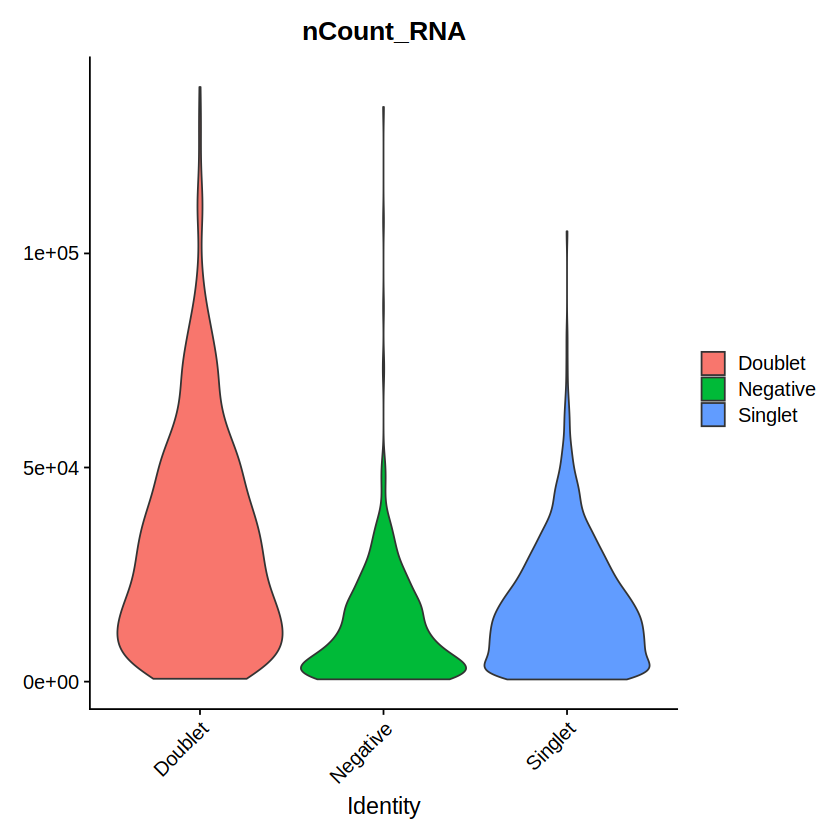

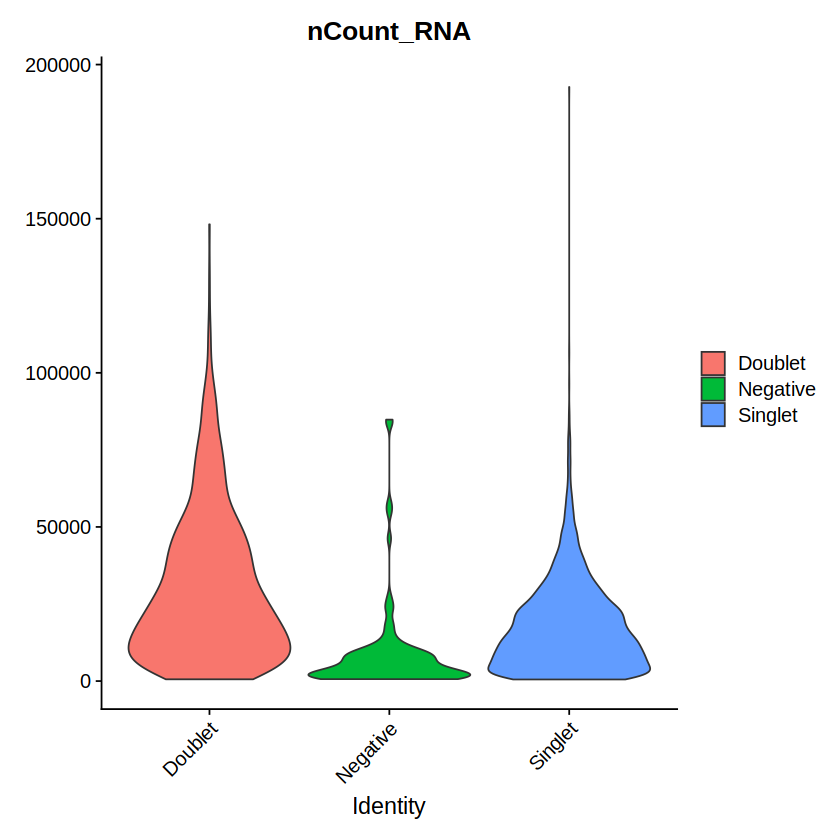

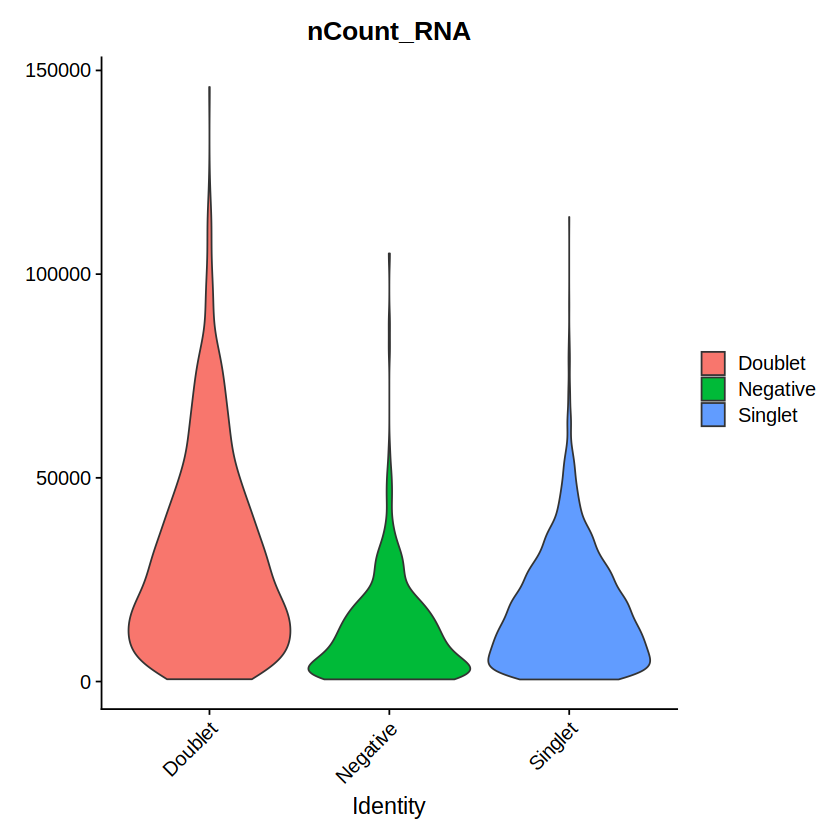

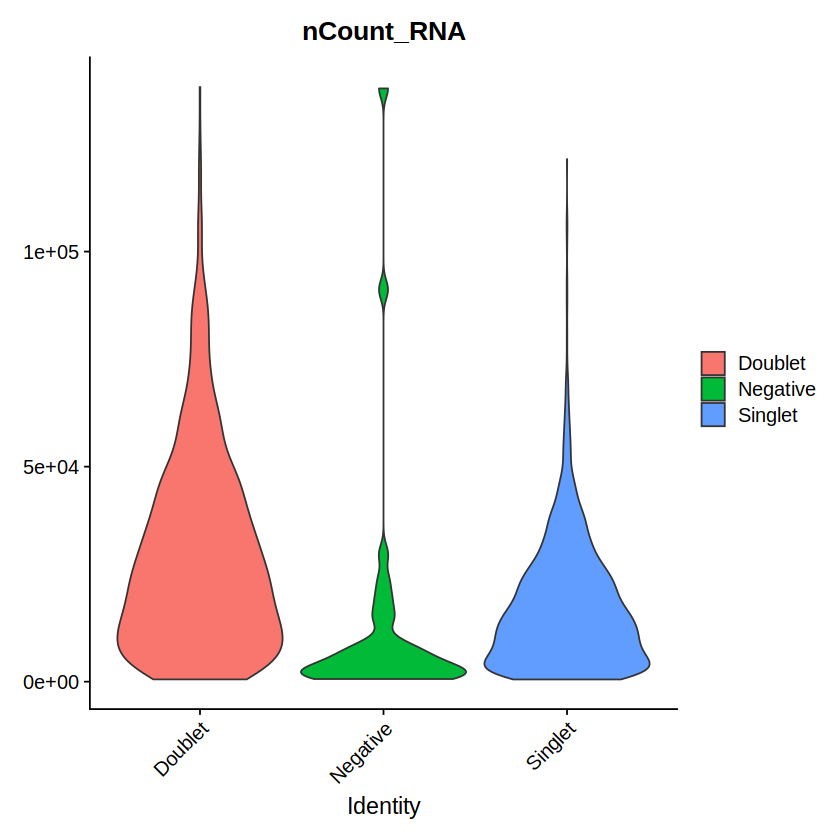

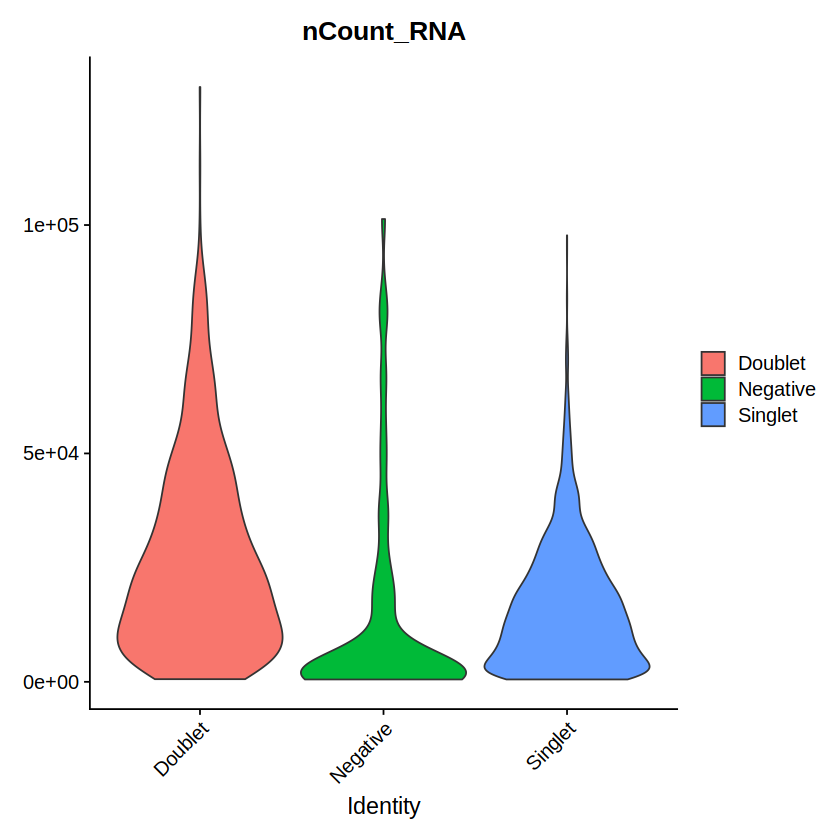

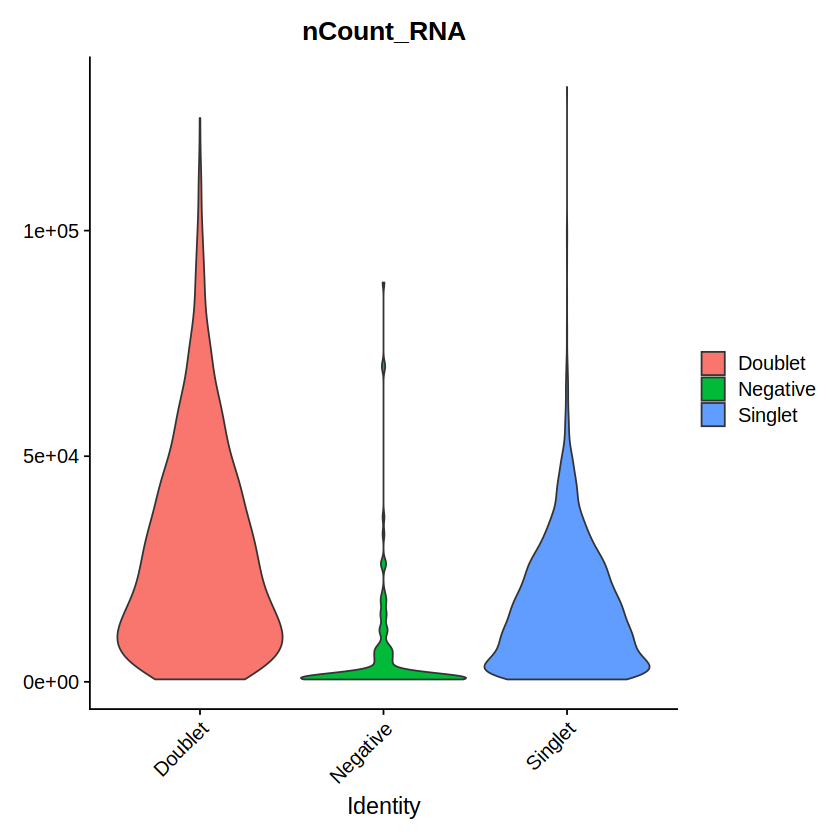

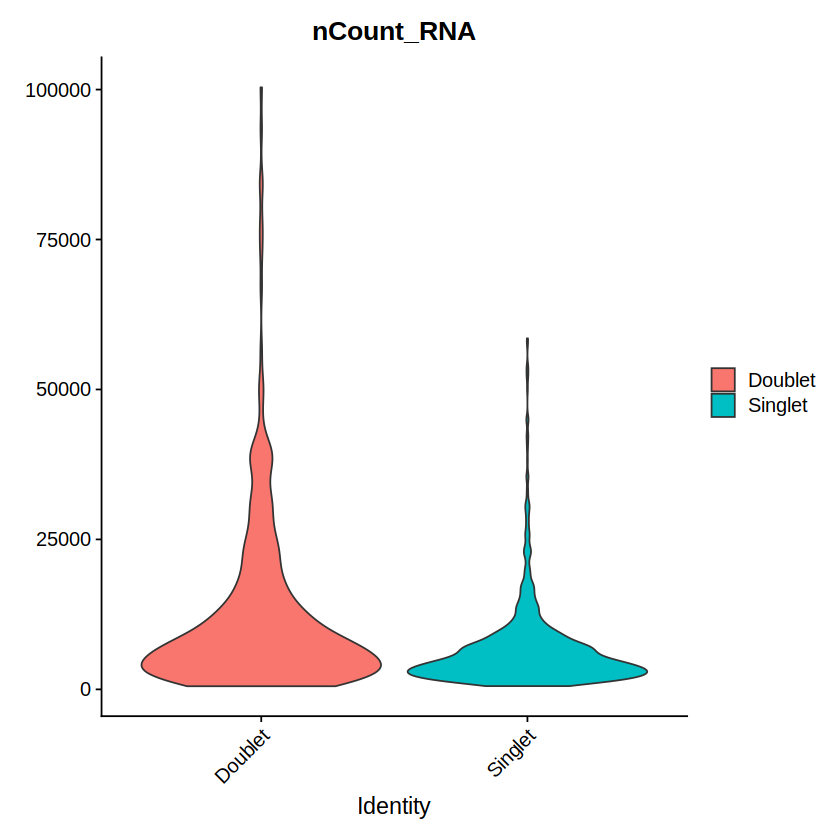

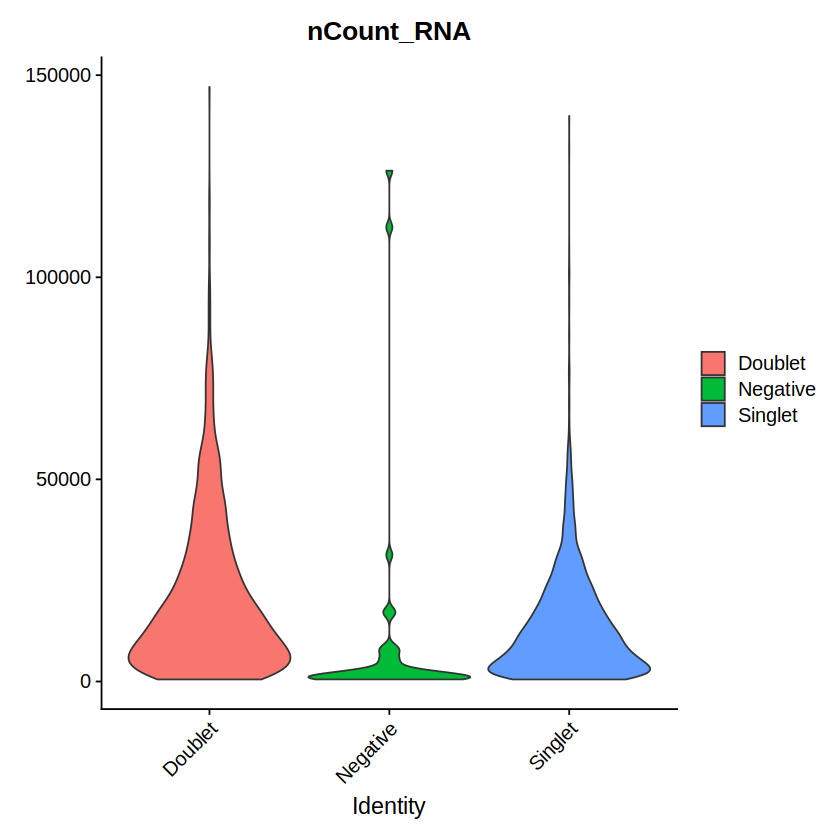

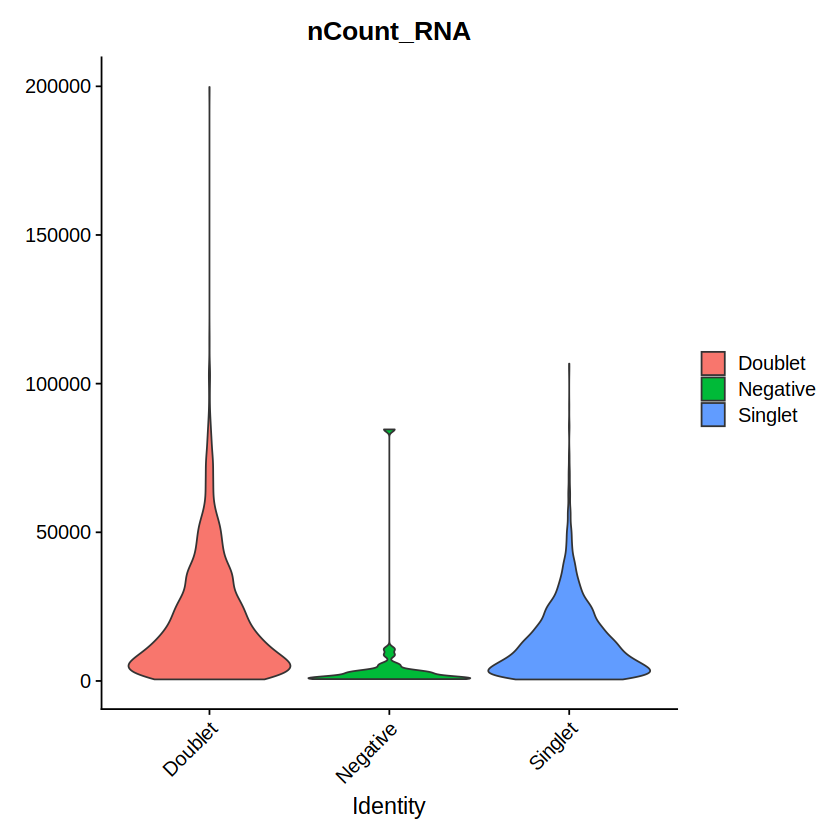

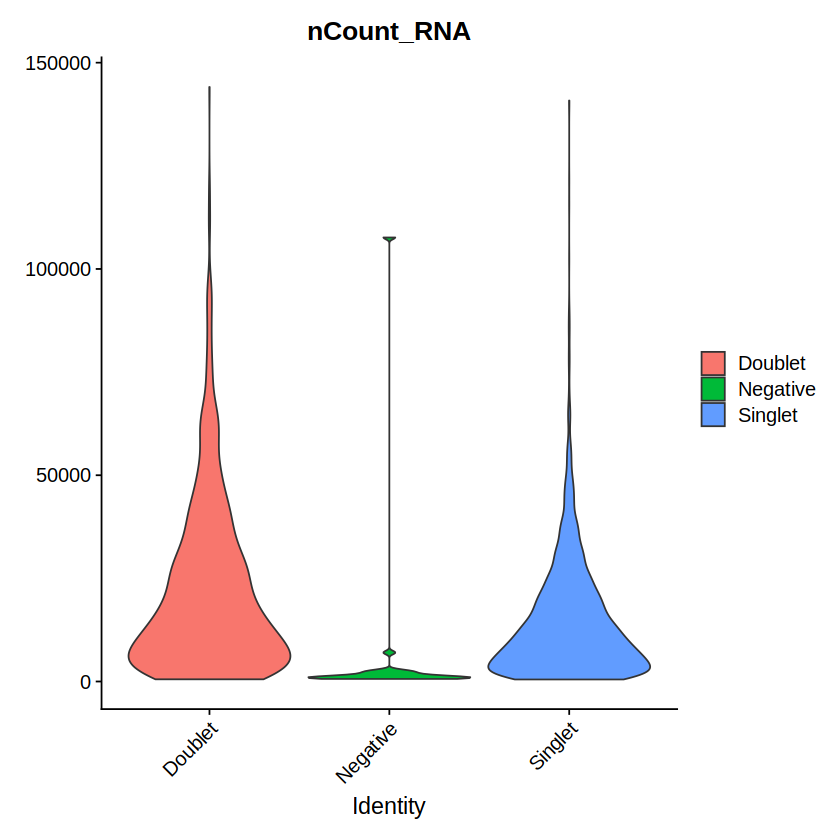

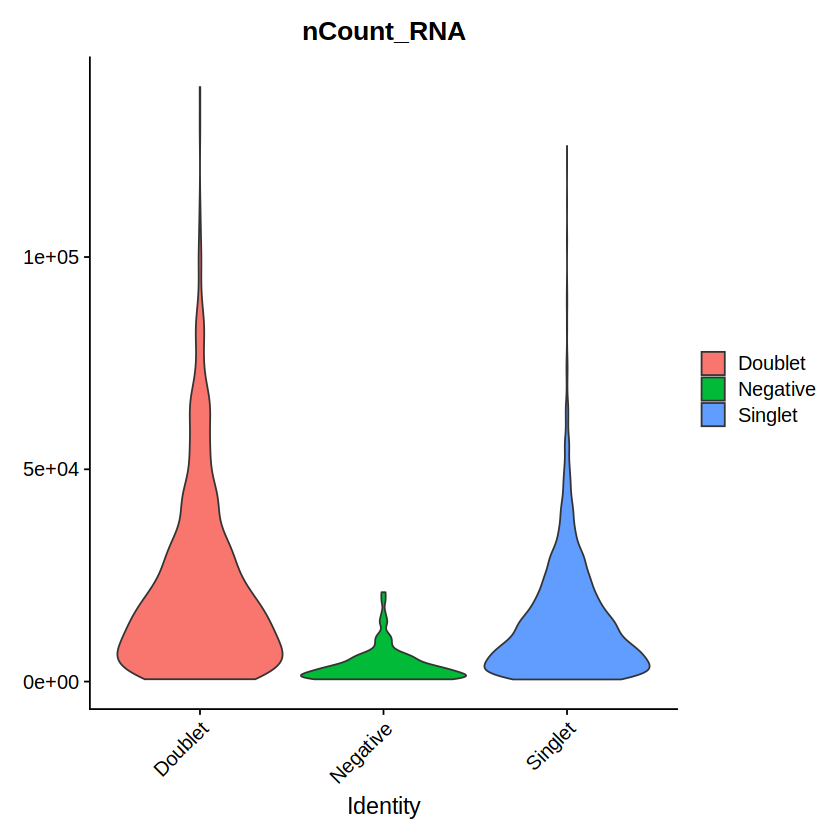

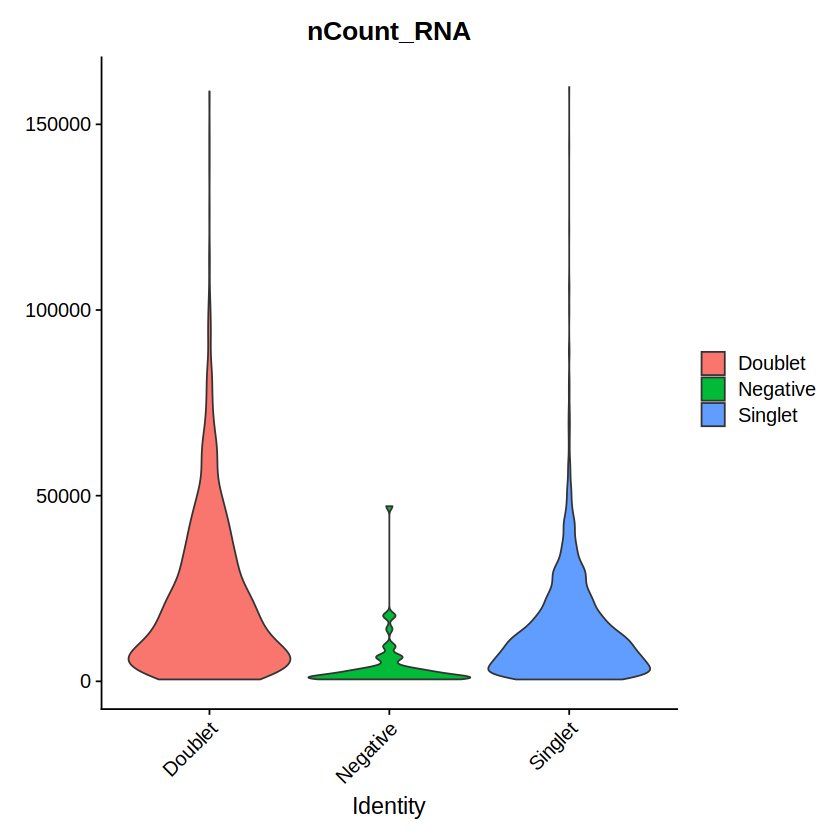

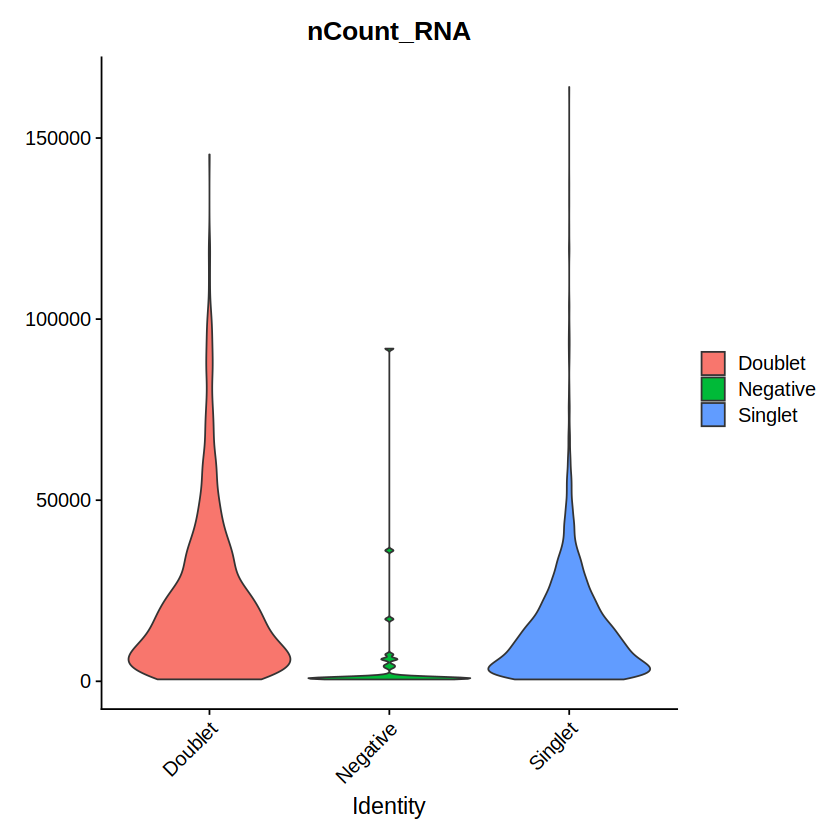

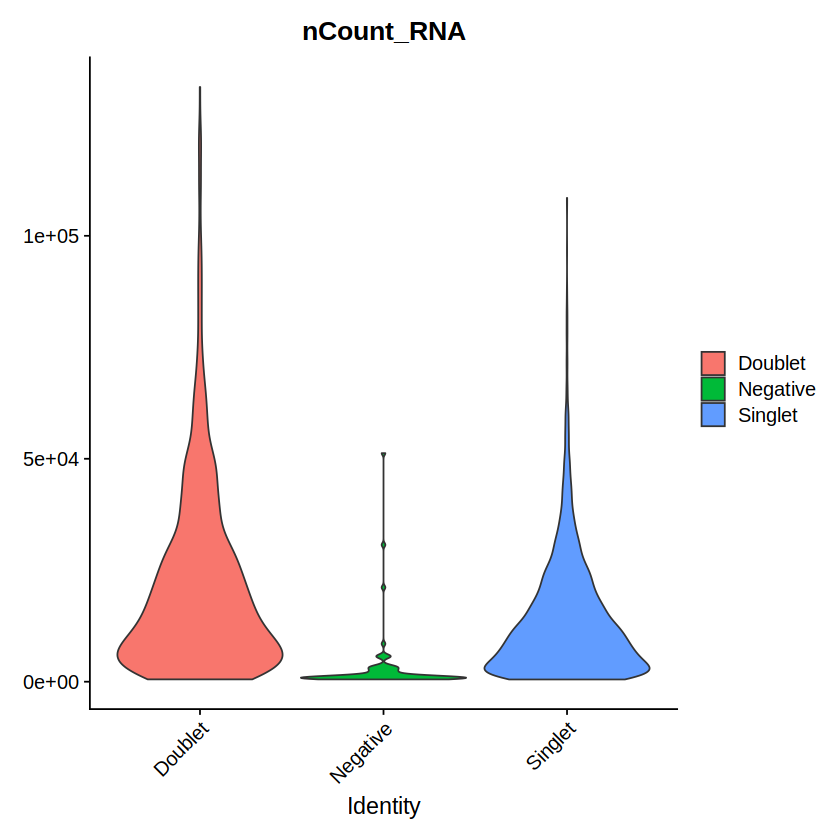

In [96]:
# Load necessary libraries
library(Seurat)
library(ggplot2)

# Assuming 'results' is the list of processed lanes
# Generate violin plots for each lane

# Define a function to create and display the violin plot for each lane
plot_violin <- function(lane_result) {
  VlnPlot(lane_result$lane, features = "nCount_RNA", group.by = "HTO_classification.global", pt.size = 0)
}

# Apply the function to each lane's result
violin_plots <- lapply(results, plot_violin)

# Display the plots in a Jupyter notebook
for (i in 1:length(violin_plots)) {
  print(violin_plots[[i]])
}

In [102]:
results[[1]]$lane@meta.data

,orig.ident,nCount_RNA,nFeature_RNA,nCount_gRNA,nFeature_gRNA,nCount_HTO,nFeature_HTO,HTO_maxID,HTO_secondID,HTO_margin,HTO_classification,HTO_classification.global,hash.ID
,<fct>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<chr>,<chr>,<dbl>,<chr>,<chr>,<fct>
AAACCTGCAGGGTTAG-1,lane1,5183,1930,0,0,917,7,Hashtag6,Hashtag12,4.2582129,Hashtag6,Singlet,Hashtag6
AAACCTGCAGTATGCT-1,lane1,4947,2270,0,0,444,7,Hashtag4,Hashtag12,4.3457931,Hashtag4,Singlet,Hashtag4
AAACCTGTCACAACGT-1,lane1,7543,2233,0,0,2216,9,Hashtag7,Hashtag1,0.5941395,Hashtag1_Hashtag7,Doublet,Doublet
AAACCTGTCCATTCTA-1,lane1,1095,792,0,0,1486,9,Hashtag7,Hashtag6,4.6629748,Hashtag7,Singlet,Hashtag7
AAACCTGTCGCTGATA-1,lane1,6428,1697,0,0,1509,9,Hashtag6,Hashtag12,4.4066110,Hashtag12_Hashtag6,Doublet,Doublet
AAACGGGAGACATAAC-1,lane1,16211,3592,0,0,5037,11,Hashtag7,Hashtag6,0.3330240,Hashtag6_Hashtag7,Doublet,Doublet
AAACGGGCACCGATAT-1,lane1,4145,1695,0,0,958,10,Hashtag2,Hashtag12,4.4481469,Hashtag2,Singlet,Hashtag2
AAACGGGTCCCAAGAT-1,lane1,4792,1824,0,0,686,6,Hashtag3,Hashtag12,3.3675913,Hashtag3,Singlet,Hashtag3
AAAGCAAAGATCCCAT-1,lane1,3206,1482,0,0,591,5,Hashtag6,Hashtag12,3.5657518,Hashtag6,Singlet,Hashtag6


In [ ]:
# Write out each lane’s metadata as a CSV
for (lane_number in seq_along(results)) {
  lane_obj   <- results[[lane_number]]$lane
  meta_data  <- lane_obj@meta.data
  out_path   <- paste0("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/hashtag_metadata/lane",
                       lane_number, "_metadata.csv")
  write.csv(meta_data, file = out_path, quote = FALSE)
}